# Prediksi Durasi Pengantaran Food Delivery: Perbandingan Algoritma Regresi
**Dataset:** `Order_delivery.csv` (1000 pesanan) | **Target:** `Delivery_Duration_Minutes` (menit)
**Algoritma:** Linear Regression, Ridge, Lasso, LARS (Least Angle Regression), Random Forest, Gradient Boosting, dibandingkan dengan baseline (tebakan rata-rata)
**Metrik:** MAE, MSE, RMSE, R²

Alur: muat data, cek kualitas, buang kolom bocor/ID, rekayasa fitur waktu, penanganan outlier, split, preprocessing dalam Pipeline, tuning dengan 5-fold CV, evaluasi pada data uji.

## 1. Persiapan & Data

In [ ]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, Lars
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 1
sns.set_style('whitegrid')

In [ ]:
df = pd.read_csv('Order_delivery.csv')
print('Ukuran data :', df.shape)
print('Missing     :', int(df.isnull().sum().sum()))
print('Duplikat    :', int(df.duplicated().sum()))
df.head()

Ukuran data : (1000, 23)
Missing     : 0
Duplikat    : 0


   Order_ID User_ID  ...  Traffic_Level  Driver_Availability
0        88   U7553  ...            Low              Offline
1       115   U9863  ...           High               Online
2       150   U7680  ...         Medium              Offline
3       227   U7722  ...            Low               Online
4       271   U8168  ...            Low               Online

[5 rows x 23 columns]

## 2. Memahami Target
Target tersebar merata di rentang 15-60 menit. Kolom `Delivery_Time` dikurangi `Order_Time` sama persis dengan target, sehingga **kedua kolom waktu itu tidak boleh dipakai sebagai fitur** (kebocoran data).

count    1000.00
mean       37.28
std         9.80
min        15.00
25%        30.00
50%        37.00
75%        45.00
max        60.00
Name: Delivery_Duration_Minutes, dtype: float64

Kolom waktu persis sama dengan target pada 100.0 % baris


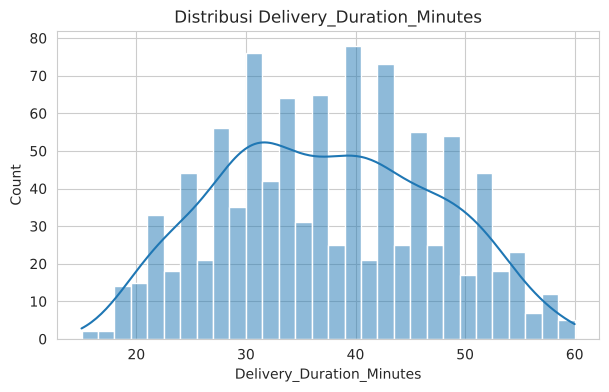

In [ ]:
target = 'Delivery_Duration_Minutes'
print(df[target].describe().round(2))

# Bukti kebocoran data: Delivery_Time - Order_Time == target
t_order = pd.to_datetime(df['Order_Time'], format='%d-%m-%Y %H:%M')
t_deliv = pd.to_datetime(df['Delivery_Time'], format='%d-%m-%Y %H:%M')
selisih = (t_deliv - t_order).dt.total_seconds() / 60
print('\nKolom waktu persis sama dengan target pada', round((selisih == df[target]).mean()*100, 1), '% baris')

plt.figure(figsize=(7, 4))
sns.histplot(df[target], bins=30, kde=True)
plt.title('Distribusi Delivery_Duration_Minutes'); plt.show()

## 3. Seleksi Fitur & Rekayasa Fitur
- Kolom ID (`Order_ID`, `User_ID`, `Restaurant_ID`, `Driver_ID`) dibuang: angka ID hanya penanda, bukan ukuran, jadi tidak boleh dipakai sebagai angka.
- `Order_Time` diubah menjadi `Order_Hour` dan `Order_DayOfWeek`; `Delivery_Time` dibuang karena bocor.
- Fitur kategorikal di-*one-hot encode*, bukan label-encode, supaya model tidak menganggap ada urutan antar kategori.

In [ ]:
# Fitur turunan dari waktu pesan (jam & hari), lalu buang kolom yang bocor / tidak bermakna
data = df.copy()
data['Order_Hour'] = t_order.dt.hour
data['Order_DayOfWeek'] = t_order.dt.dayofweek

drop_cols = [
    'Order_ID', 'User_ID', 'Restaurant_ID', 'Driver_ID',   # ID: hanya penanda, bukan ukuran
    'Order_Time', 'Delivery_Time',                         # Delivery_Time bocor ke target
]
data = data.drop(columns=drop_cols)

num_cols = data.select_dtypes(include='number').columns.drop(target).tolist()
cat_cols = data.select_dtypes(exclude='number').columns.tolist()
print('Numerik    :', num_cols)
print('Kategorikal:', cat_cols)

Numerik    : ['Quantity', 'Total_Price', 'Restaurant_Lat', 'Restaurant_Lon', 'Customer_Lat', 'Customer_Lon', 'Driver_Lat', 'Driver_Lon', 'Delivery_Distance_km', 'Order_Hour', 'Order_DayOfWeek']
Kategorikal: ['Item_Name', 'City', 'Payment_Method', 'Order_Status', 'Driver_Vehicle', 'Traffic_Level', 'Driver_Availability']


## 4. Outlier
Outlier dicek dengan IQR pada fitur transaksi. Koordinat tidak di-clip karena perbedaan lokasi antar kota bukan outlier.

In [ ]:
# Cek outlier (IQR) hanya pada fitur nilai transaksi. Koordinat lat/lon TIDAK di-clip:
# koordinat berbeda antar kota itu wajar, bukan outlier (clip akan merusak lokasi).
out_cols = ['Quantity', 'Total_Price', 'Delivery_Distance_km']
Q1, Q3 = data[out_cols].quantile(.25), data[out_cols].quantile(.75)
IQR = Q3 - Q1
lo, hi = Q1 - 1.5*IQR, Q3 + 1.5*IQR
n_out = ((data[out_cols] < lo) | (data[out_cols] > hi)).sum()
print('Jumlah outlier per kolom:'); print(n_out)
data[out_cols] = data[out_cols].clip(lo, hi, axis=1)  # outlier diganti batas terdekat; target tidak diubah

Jumlah outlier per kolom:
Quantity                0
Total_Price             7
Delivery_Distance_km    0
dtype: int64


## 5. Eksplorasi: Korelasi dengan Target

Delivery_Distance_km    0.058
Quantity               -0.056
Order_Hour             -0.044
Order_DayOfWeek        -0.031
Driver_Lon              0.021
Name: Delivery_Duration_Minutes, dtype: float64


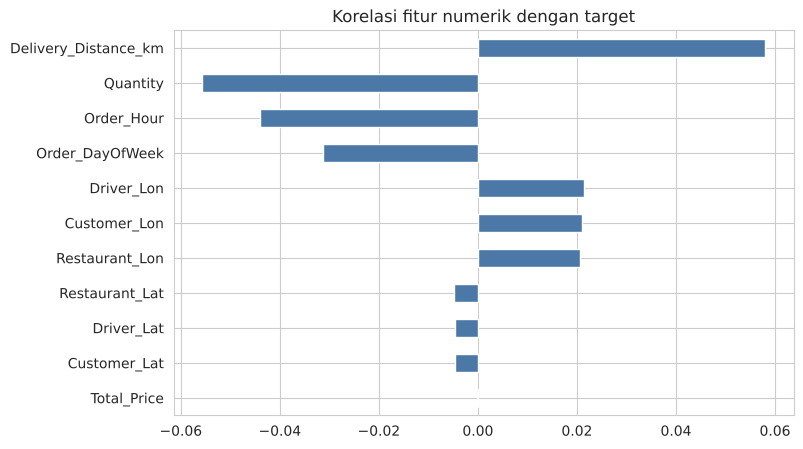

In [ ]:
# Korelasi fitur numerik dengan target
corr = data[num_cols + [target]].corr()[target].drop(target).sort_values(key=abs, ascending=False)
plt.figure(figsize=(8, 5))
corr.plot(kind='barh', color='#4C78A8')
plt.title('Korelasi fitur numerik dengan target'); plt.gca().invert_yaxis(); plt.show()
print(corr.round(3).head(5))

Korelasi tertinggi hanya sekitar 0,06, artinya tidak ada fitur yang berhubungan kuat dengan durasi pengantaran.

## 6. Split Data & Pipeline
Data dibagi 80% latih dan 20% uji (`random_state=1`). Scaling dan encoding dimasukkan ke dalam Pipeline sehingga hanya belajar dari data latih.

In [ ]:
X = data.drop(columns=[target])
y = data[target]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print('Latih:', X_train.shape, '| Uji:', X_test.shape)

# Preprocessing masuk Pipeline: scaler & encoder hanya belajar dari data latih (tanpa kebocoran)
pre = ColumnTransformer([
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols),
])
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

Latih: (800, 18) | Uji: (200, 18)


## 7. Pelatihan & Tuning Hyperparameter
Hyperparameter Ridge, Lasso, LARS, Random Forest, dan Gradient Boosting dicari dengan `GridSearchCV` (5-fold, skor R²) hanya pada data latih.

In [ ]:
def pipe(model): return Pipeline([('pre', pre), ('model', model)])

# Model + grid hyperparameter (dituning dengan 5-fold CV pada data latih, skor R2)
# Referensi tiap algoritma (lengkapnya ada di Daftar Pustaka paling bawah):
#  - Baseline            : pembanding wajib; model dianggap berguna hanya jika R2 > baseline.
#  - Linear Regression   : Shirahama (2025), "Evidence-Based Model Selection: When and Why Linear Models
#                          Outperform Gradient Boosting Decision Trees", J. Intelligence Science in Local
#                          Research 2(1), 1-19. | Cenita et al. (2023), Int. J. Computing Sciences Research 7, 2052-2065.
#  - Ridge               : Okolie et al. (2025), "Comparing OLS, Ridge, and Lasso Regression for Multicollinearity
#                          Mitigation in Linear Models", IJMSO 11(4), 46-56. (Ridge: generalisasi terbaik)
#  - Lasso               : Okolie et al. (2025), idem. (Lasso: seleksi fitur, koefisien bisa 0)
#  - LARS                : Hirose (2025), "Least angle regression in tangent space and LASSO for generalized
#                          linear models", Behaviormetrika 52, 179-196. doi:10.1007/s41237-024-00237-2
#  - Random Forest       : Garg et al. (2025), "Food Delivery Time Prediction in Indian Cities Using Machine
#                          Learning Models", arXiv:2503.15177. | Bakirçay University (2024), time prediction in food delivery.
#  - Gradient Boosting   : Grinsztajn et al. (2022), "Why do tree-based models still outperform deep learning on
#                          typical tabular data?", NeurIPS 2022 Datasets & Benchmarks. | Cenita et al. (2023), idem.
specs = {
    'Baseline (rata-rata)': (DummyRegressor(strategy='mean'), {}),
    'Linear Regression':    (LinearRegression(), {}),
    'Ridge':   (Ridge(), {'model__alpha': [0.1, 1, 10, 100, 300, 1000]}),
    'Lasso':   (Lasso(max_iter=20000), {'model__alpha': [0.001, 0.01, 0.1, 0.5, 1, 2]}),
    'LARS':    (Lars(), {'model__n_nonzero_coefs': [1, 3, 5, 10, 20]}),
    'Random Forest': (RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE, n_jobs=-1),
                      {'model__max_depth': [3, 6, None], 'model__min_samples_leaf': [5, 20]}),
    'Gradient Boosting': (GradientBoostingRegressor(random_state=RANDOM_STATE),
                      {'model__n_estimators': [50, 150], 'model__learning_rate': [0.01, 0.05],
                       'model__max_depth': [2, 3], 'model__subsample': [0.8]}),
}

fitted, best_params, cv_r2 = {}, {}, {}
for name, (m, grid) in specs.items():
    if grid:
        gs = GridSearchCV(pipe(m), grid, cv=cv, scoring='r2', n_jobs=-1).fit(X_train, y_train)
        fitted[name], best_params[name], cv_r2[name] = gs.best_estimator_, gs.best_params_, gs.best_score_
    else:
        fitted[name] = pipe(m).fit(X_train, y_train)
        cv_r2[name] = cross_val_score(pipe(m), X_train, y_train, cv=cv, scoring='r2').mean()
        best_params[name] = '-'
pd.DataFrame({'Parameter terbaik': best_params, 'R2 CV (latih)': pd.Series(cv_r2).round(4)})

                                                      Parameter terbaik  R2 CV (latih)
Baseline (rata-rata)                                                  -        -0.0061
Linear Regression                                                     -        -0.0568
Ridge                                            {'model__alpha': 1000}        -0.0047
Lasso                                             {'model__alpha': 0.5}        -0.0055
LARS                                      {'model__n_nonzero_coefs': 3}        -0.0025
Random Forest         {'model__max_depth': 3, 'model__min_samples_le...        -0.0091
Gradient Boosting     {'model__learning_rate': 0.01, 'model__max_dep...        -0.0044

## 8. Evaluasi pada Data Uji

In [ ]:
rows = []
for name, m in fitted.items():
    p = m.predict(X_test)
    rows.append([name, mean_absolute_error(y_test, p), mean_squared_error(y_test, p),
                 np.sqrt(mean_squared_error(y_test, p)), r2_score(y_test, p)])
hasil = (pd.DataFrame(rows, columns=['Model', 'MAE', 'MSE', 'RMSE', 'R2'])
         .set_index('Model').round(4).sort_values('R2', ascending=False))
hasil

                         MAE       MSE     RMSE      R2
Model                                                  
Baseline (rata-rata)  8.0470   92.1454   9.5992 -0.0320
Lasso                 8.0639   92.3801   9.6115 -0.0347
Ridge                 8.0778   92.4449   9.6148 -0.0354
LARS                  8.0886   92.7284   9.6296 -0.0386
Gradient Boosting     8.1006   92.8003   9.6333 -0.0394
Random Forest         8.1777   94.6458   9.7286 -0.0600
Linear Regression     8.4369  100.9842  10.0491 -0.1310

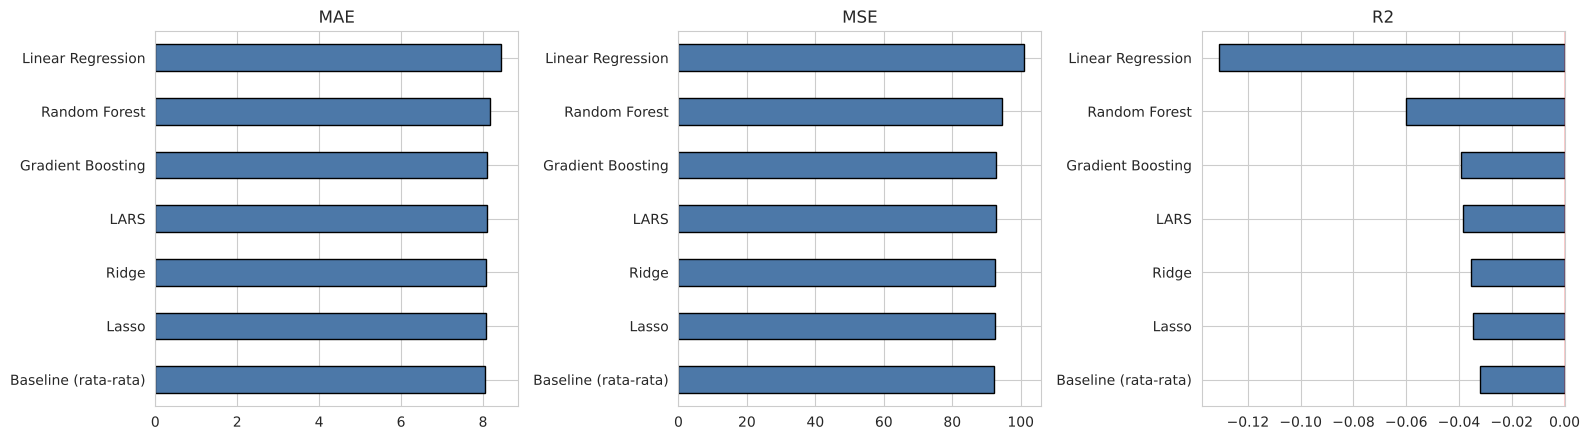

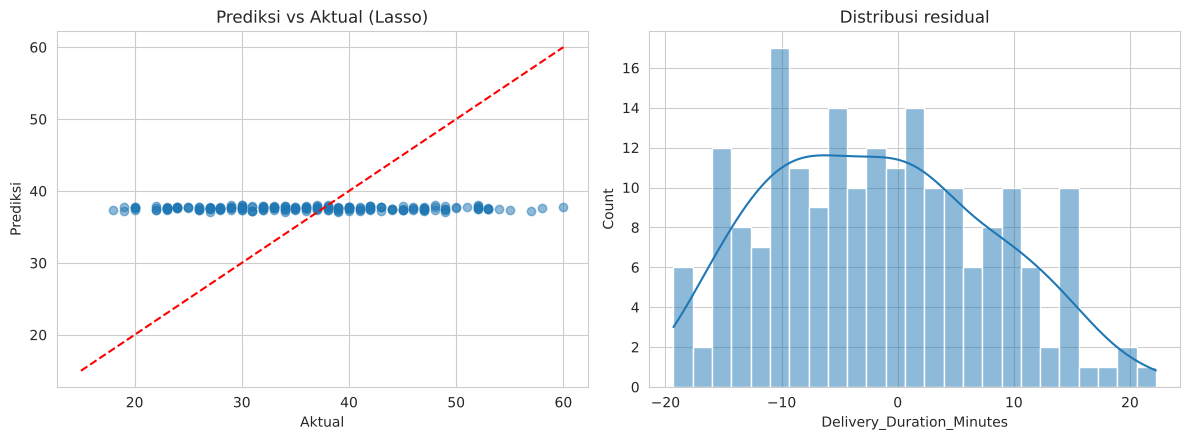

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, metric in zip(ax, ['MAE', 'MSE', 'R2']):
    hasil[metric].sort_values(ascending=(metric != 'R2')).plot(kind='barh', ax=a, color='#4C78A8', edgecolor='black')
    a.set_title(metric); a.set_ylabel('')
    if metric == 'R2': a.axvline(0, color='red', lw=1)
plt.tight_layout(); plt.show()

# Prediksi vs aktual & residual untuk model terbaik
best = hasil.index[0]
if best.startswith('Baseline'): best = hasil.index[1]
pred = fitted[best].predict(X_test)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].scatter(y_test, pred, alpha=.5); ax[0].plot([15, 60], [15, 60], 'r--')
ax[0].set_xlabel('Aktual'); ax[0].set_ylabel('Prediksi'); ax[0].set_title(f'Prediksi vs Aktual ({best})')
sns.histplot(y_test - pred, bins=25, kde=True, ax=ax[1]); ax[1].set_title('Distribusi residual')
plt.tight_layout(); plt.show()

## 9. Analisis Hasil
**Temuan utama**
- **Tidak ada model yang mengalahkan baseline.** Semua model punya R² ≤ 0 (setara atau lebih buruk dari menebak rata-rata 37 menit). Lasso paling dekat ke baseline (MAE 8,06; MSE 92,38; R² -0,035), disusul Ridge, LARS, dan Gradient Boosting.
- **Linear Regression dan Random Forest paling buruk** (R² -0,131 dan -0,060). Tanpa regularisasi atau pembatasan, model ini menyesuaikan diri ke noise (*overfitting*). Hal ini konsisten dengan temuan bahwa regularisasi (Ridge/Lasso) memberi generalisasi lebih baik saat fitur berkorelasi (Okolie dkk., 2025).
- **Penyebabnya ada di data.** Korelasi tertinggi fitur ke target hanya ±0,06, target tersebar rata 15-60 menit, dan rata-rata durasi hampir sama di tiap kategori lalu lintas dan kendaraan. Pola ini khas data sintetis: tidak ada sinyal yang bisa dipelajari, jadi kompleksitas model tidak membantu.
- Pada penelitian prediksi waktu pengantaran dengan data bersinyal nyata, model ensemble (LightGBM/XGBoost) unggul jauh (Garg dkk., 2025; Bakırçay, 2024). Perbedaan dengan hasil di sini menunjukkan kualitas fitur lebih menentukan daripada pilihan algoritma.

**Catatan metodologis:** versi awal notebook (label-encode semua kolom termasuk ID) sempat memberi R² 0,09 untuk Linear Regression. Angka itu tidak stabil: setelah ID dibuang dan preprocessing dilakukan benar, R² turun ke negatif. Jadi R² positif sebelumnya kebetulan pada satu split, bukan kemampuan prediksi.

**Cara membaca metrik**
- **MAE dan MSE** tidak punya batas 1. Nilainya bergantung skala target (menit), jadi dibandingkan antar model; makin kecil makin baik. MAE 8 berarti rata-rata prediksi meleset ±8 menit.
- **R²** maksimal 1. Nilai 0 sama dengan menebak rata-rata, negatif lebih buruk dari menebak rata-rata.

## 10. Dasar Pemilihan Algoritma Regresi
Pemilihan dipengaruhi tiga hal: **jenis data**, **ukuran dataset**, dan **linearitas** hubungan fitur-target.

| Algoritma | Cocok untuk | Skala data | Real-time | Domain sensitif (butuh interpretasi) |
|---|---|---|---|---|
| Linear Regression | Hubungan kira-kira linear, fitur numerik; pada kondisi tertentu bisa mengungguli boosting (Shirahama, 2025) | Kecil sampai besar | Ya, prediksi sangat cepat | Cocok, koefisien mudah dijelaskan |
| Ridge | Fitur banyak dan saling berkorelasi (multikolinearitas); generalisasi lebih stabil (Okolie dkk., 2025) | Kecil sampai menengah | Ya | Cocok |
| Lasso | Banyak fitur, ingin seleksi fitur otomatis (koefisien jadi 0), lebih mudah diinterpretasi (Okolie dkk., 2025) | Kecil sampai menengah | Ya | Cocok, model ringkas |
| LARS | Fitur berdimensi tinggi; menambah fitur bertahap, jalurnya setara Lasso (Hirose, 2025) | Kecil sampai menengah | Ya | Cukup |
| Random Forest | Hubungan non-linear dan interaksi antar fitur, data tabular campuran (Garg dkk., 2025) | Menengah sampai besar | Kurang ideal: model besar, lebih lambat | Kurang, sulit dijelaskan |
| Gradient Boosting | Non-linear, akurasi tinggi pada data tabular berukuran menengah (Grinsztajn dkk., 2022; Cenita dkk., 2023) | Menengah sampai besar | Prediksi cepat, pelatihan lebih lama | Kurang, perlu tuning, rawan overfit |

**Ringkas:** data kecil dengan pola linear atau fitur berkorelasi, pakai keluarga linear (Linear/Ridge/Lasso). Data lebih besar dengan pola non-linear, pakai ensemble (Random Forest/Gradient Boosting). Domain sensitif (misalnya kesehatan atau keuangan) butuh model yang bisa dijelaskan, jadi model linear lebih disukai.

**Penerapan pada dataset ini:** 1000 baris tergolong kecil, dan hubungan fitur-target nyaris tidak ada. Karena itu model sederhana ber-regularisasi (Lasso/Ridge) paling aman, sedangkan model kompleks tidak memberi keuntungan.

## 11. Kesimpulan
1. Dari enam algoritma yang diuji, **tidak ada yang melampaui baseline** pada dataset ini. **Lasso** adalah yang terbaik dengan selisih sangat kecil (MAE 8,06; MSE 92,38; R² -0,035), karena regularisasi L1 menekan fitur yang tidak informatif.
2. Hasil rendah bukan karena kesalahan model, tetapi karena fitur tidak punya hubungan berarti dengan durasi pengantaran (korelasi maksimum ±0,06).
3. Agar prediksi berguna, diperlukan data yang lebih kaya (misalnya jarak rute sebenarnya, cuaca, waktu persiapan restoran, beban pengemudi) dan jumlah data yang lebih besar.
4. Kolom `Delivery_Time` wajib dibuang dari fitur karena bocor ke target.

## Daftar Pustaka
1. Okolie, F.A., Fagbemigun, B.O., Taiwo, O.E., & Adekola, E.O. (2025). Comparing Ordinary Least Squares, Ridge, and Lasso Regression for Multicollinearity Mitigation in Linear Models. *International Journal of Mathematical Sciences and Optimization: Theory and Applications*, 11(4), 46-56. https://ijmso.unilag.edu.ng/article/view/2914
2. Hirose, Y. (2025). Least angle regression in tangent space and LASSO for generalized linear models. *Behaviormetrika*, 52, 179-196. https://doi.org/10.1007/s41237-024-00237-2
3. Shirahama, N. (2025). Evidence-Based Model Selection: When and Why Linear Models Outperform Gradient Boosting Decision Trees. *Journal of Intelligence Science in Local Research*, 2(1), 1-19. https://ypir.lib.yamaguchi-u.ac.jp/sc/2078
4. Cenita, J.A.S., Asuncion, P.R.F., & Victoriano, J.M. (2023). Performance Evaluation of Regression Models in Predicting the Cost of Medical Insurance. *International Journal of Computing Sciences Research*, 7, 2052-2065. https://arxiv.org/abs/2304.12605
5. Garg, A., Ayaan, M., Parekh, S., & Udandarao, V. (2025). Food Delivery Time Prediction in Indian Cities Using Machine Learning Models. arXiv:2503.15177. https://arxiv.org/abs/2503.15177
6. Grinsztajn, L., Oyallon, E., & Varoquaux, G. (2022). Why do tree-based models still outperform deep learning on typical tabular data? *NeurIPS 2022, Datasets and Benchmarks Track*. https://nips.cc/virtual/2022/poster/55627
7. (2024). A comparative analysis of machine learning models for time prediction in food delivery operations. İzmir Bakırçay Üniversitesi (repositori; nama penulis tidak tercantum). https://acikerisim.bakircay.edu.tr/items/d593d156-6e65-45db-aa95-765ce197d2af

*Catatan: periksa ulang detail sitasi (penulis lengkap, DOI) di halaman sumber sebelum dikumpulkan. Referensi no. 7 tidak mencantumkan penulis di repositori, lengkapi atau ganti jika dosen mewajibkan format lengkap.*